In [129]:
# From ref design
from pynq import Overlay
import xrfclk
from pynq import PL

# ADC
from adc_scope import AdcScope
import matplotlib.pyplot as plt
%matplotlib inline

# DAC
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [130]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals
ol = Overlay("awg_adc_v4.bit")         # after xrfclk.set_ref_clks(...) as usual

In [131]:
awg = AWG(window=100 * ns, bitfile=ol)

Window = 0.0993 us  (976 samples, 61 clock cycles)  [requested 0.1000 us]


1e-09 9830400000.0 1e-08 98 61
Window: 0.0993 us = 976 samples = 61 clock cycles (MAX_POINTS)
DAC full scale: +-0.250 V peak (CW -2.04 dBm into 50 ohm)
  DAC_B slot z: peak     0.00 mV  (  -inf dBm)
  DAC_B slot x: peak   100.00 mV  (-10.00 dBm)
  DAC_A slot z: peak     0.00 mV  (  -inf dBm)
  DAC_A slot x: peak   100.00 mV  (-10.00 dBm)


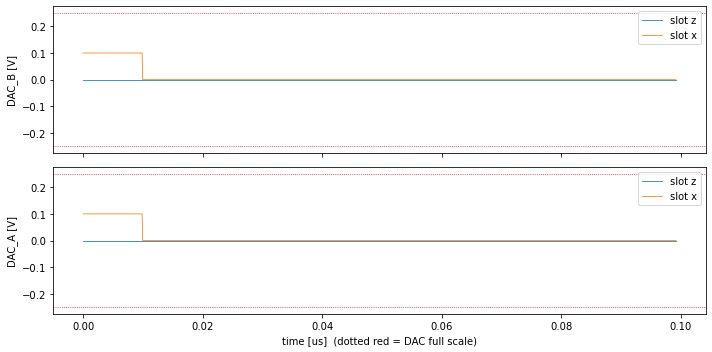

In [132]:
mysig = 0.1 * np.sin(2*np.pi*100e6*awg.t)  # 164 mV peak

pulse_width = 10 * ns
pulsewidth_insamples = round(pulse_width * DAC_SR)

print(ns, DAC_SR, pulse_width, pulsewidth_insamples, awg.max_points)

mypulse = 0.1 * np.append( np.ones(pulsewidth_insamples), np.zeros(len(awg.t) - pulsewidth_insamples) )

awg.set_waveform("DAC_A", "x", mypulse)
awg.set_waveform("DAC_B", "x", mypulse)
# Not played by default
awg.set_waveform("DAC_A", "z", 0)
awg.set_waveform("DAC_B", "z", 0)
awg.summary()   # peak level of every slot (+ clipping warning)
awg.plot()
plt.show()

In [133]:
awg.connect()    # load bitstream, program clocks, reset the AWG logic
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs

DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']


In [134]:
sc = AdcScope(ol)                      # starts the ADC clock (MMCM) and checks the ADC streams

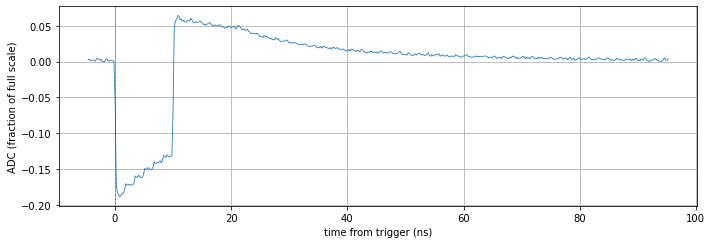

In [144]:
sc.configure(trigger="falling", level=-0.05, pre_ns=0, length_ns=100)
t, y = sc.acquire()                    # t in ns, 0 = trigger; y in fraction of full scale
sc.plot(t, y)

In [167]:
offset_ns, spread_ns = sc.calibrate_awg0()
# print("initial offset DAC->ADC in ns:", offset_ns, "\nspread_ns:", spread_ns)
cpt = 1

while(spread_ns > 0.01): # Means not locked, do again
    offset_ns, spread_ns = sc.calibrate_awg0()
    cpt=cpt+1

print("final offset DAC->ADC in ns:", offset_ns, "\nspread_ns:", spread_ns, "\nattempts needed:", cpt)

final offset DAC->ADC in ns: 21.826790331489278 
spread_ns: 0.0017838687585714648 
attempts needed: 1


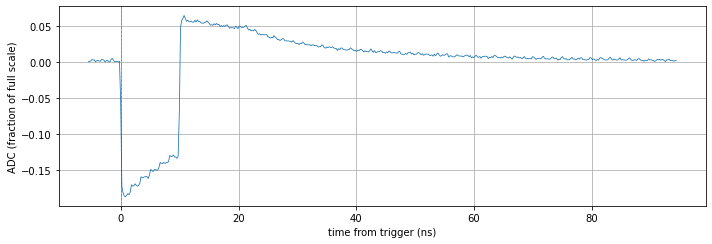

In [157]:
sc.configure(trigger="awg0", pre_ns=-offset_ns, length_ns=100)
t, y = sc.acquire()                    # t in ns, 0 = trigger; y in fraction of full scale
sc.plot(t, y)

In [ ]:
### SCAN FREQ
